# تشخيص أعطال المحامل الصناعية واكتشاف الأعطال الجديدة — النسخة النهائية
**Industrial Bearing Fault Diagnosis: Fault Classification and Novelty Detection on Unseen Bearings (CWRU)**

## 1. نظرة عامة
يقدّم هذا الدفتر النسخة النهائية النظيفة من المشروع. هو **دفتر مستقل**: يقرأ ملفات CWRU الخام، ويستخرج الخصائص، ويعيد حساب كل نتائج
النموذج النهائي بالبروتوكول المدقَّق، ثم يقارن كل رقم بالنتائج المحفوظة من مرحلة التطوير، ويحمّل النموذج المحفوظ ويستخدمه في الاستدلال.
دفتر التطوير (`Industrial_Bearing_ML_Project_Improved.ipynb`) يبقى كما هو سجلًا كاملًا لكل التجارب.

| العنصر | القيمة |
|---|---|
| النموذج النهائي | Random Forest (300 شجرة، max_features=0.5، min_samples_leaf=2) داخل Pipeline: SimpleImputer ← StandardScaler ← RF |
| الملف | `improvement/models/improved_fault_classifier_v2.joblib` |
| الخصائص | 40 خاصية فيزيائية (المجموعة C): طيف الغلاف التربيعي بعد التبييض السبكتروني، وبروز القمة المحلي عند BPFO وBPFI وBSF |
| التمثيل | نوافذ 2 ثانية (24000 عينة عند 12 kHz) بتداخل 50% |
| وحدة التعميم | **المحمل الفيزيائي** (26 محملًا) |

## 2. مشكلة البحث والأهداف
**المشكلة:** نموذج يصنّف نوع عطل المحمل جيدًا على تسجيلات **محمل رآه** (بحمل آخر) قد يفشل على **محمل جديد**.
وهذا هو السؤال العملي في الصيانة التنبؤية: هل يعمل النموذج على آلة أو محمل لم يُدرَّب عليه؟

**الأهداف:**
1. تصنيف ثلاثة أنواع أعطال (الحلقة الداخلية، والحلقة الخارجية، وعنصر التدحرج/الكرة) على **محامل لم تظهر في التدريب**.
2. قياس الانتقال إلى **نوع محمل وحساس مختلفين** (Cross-End).
3. اكتشاف **نوع عطل لم يُر أثناء التدريب**، بمعدل إنذار كاذب مُقاس بصدق.
4. تحليل الأخطاء المتبقية، خصوصًا في الحلقة الخارجية.

## 3. البيانات وحدود التجربة
- **المصدر:** مركز بيانات المحامل بجامعة Case Western Reserve (CWRU)، و97 ملف MAT في المجلد `CWRU_Bearing_Dataset_Pt2`:
  - **DE48:** عيوب في محمل جهة القيادة (SKF 6205)، بتردد 48 kHz.
  - **FE12:** عيوب في محمل جهة المروحة (SKF 6203)، بتردد 12 kHz.
- **الفئات الموجودة فعليًا ثلاث فقط، ولا توجد فئة سليمة.** لذلك «اكتشاف الجديد» هنا هو اكتشاف **نوع عطل لم يُمثَّل في الفئات المعروفة**، لا الفصل بين سليم ومعطوب.
- كل عيب (نوع × قطر × موضع) مزروع في **محمل فيزيائي واحد** سُجّل حتى 4 أحمال، فالبيانات تضم **26 محملًا** فقط (6 كرة، و6 حلقة داخلية، و14 خارجية).
- العيوب مصطنعة بالتفريغ الكهربائي في منصة مخبرية واحدة. النتائج **لا تمثل تحققًا خارجيًا مستقلًا** على آلات صناعية.
- الملف 174 مستبعد لأن متغيراته باسم X173 ولا يمكن التحقق من هويته، فيبقى 96 ملفًا.

## 4. المنهجية وتصميم التقييم
**لماذا المحمل هو وحدة التقسيم؟** تقسيم الملفات عشوائيًا (كما في الدفتر الأول) يضع تسجيلات المحمل نفسه بأحمال مختلفة في التدريب والاختبار.
فتصبح الدقة قياسًا لـ«التعرف على محمل مألوف». في الدفتر الأول ظهر 94% من محامل الاختبار في التدريب.

| التقييم | التعريف | الدور |
|---|---|---|
| **LOBO-26** | حجب محمل واحد في كل مرة (26 طية)، حتمي بلا بذرة | التقدير الرئيسي لمحمل جديد من النوع نفسه |
| **Cross-End** | تدريب على 13 محمل DE واختبار على 13 محمل FE، وبالعكس | نقل إلى نوع محمل وحساس مختلفين؛ لم يُستخدم في أي اختيار |
| **بذور متوازنة إضافية 5–9** | 5 طيات طبقية على جدول المحامل (عدد محامل متوازن لكل فئة) | تأكيد قرار النموذج على تقسيمات لم تدخل أي اختيار |
| **اكتشاف الجديد** | حجب فئة كاملة؛ تدريب ومعايرة واختبار على محامل منفصلة؛ بذور 100–104 | معدل إنذار كاذب واكتشاف فعليان |

**مستويات القياس:** النافذة (2 ثانية)، و**الملف** (متوسط احتمالات نوافذ التسجيل؛ وهو مستوى القرار العملي)، و**المحمل** (متوسط كل تسجيلاته).
المقياس الرئيسي **Macro-F1 على مستوى الملف**. والانحراف المعياري بين البذور يقيس حساسية التقسيم، وليس فترة ثقة.
فترة الثقة لـ LOBO-26 محسوبة بـ **Bootstrap عنقودي على المحامل**.

## 5. إعداد البيئة والتحقق من المكتبات
المسارات تُحدَّد تلقائيًا ولا تُكتب مطلقة في الكود: `PROJECT_DIR` و`CWRU_DATA_DIR` إن وُجدا، وإلا مجلد المشروع الذي يحتوي هذا الدفتر،
والبيانات في مجلد مجاور باسم `CWRU_Bearing_Dataset_Pt2`. على Colab يُربط Google Drive إن لم يكن مربوطًا.

In [1]:
import os, sys, json, time, glob, hashlib, warnings, platform, importlib, subprocess
from pathlib import Path
for _pkg, _mod in [('arabic-reshaper', 'arabic_reshaper'), ('python-bidi', 'bidi'), ('lightgbm', 'lightgbm')]:
    try:
        importlib.import_module(_mod)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', _pkg], check=True)
import numpy as np, pandas as pd, scipy, scipy.io as sio
from scipy import signal, stats
import matplotlib, matplotlib.pyplot as plt, seaborn as sns
import sklearn, joblib, lightgbm
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score)
from lightgbm import LGBMClassifier
from IPython.display import display
import arabic_reshaper
from bidi.algorithm import get_display
warnings.filterwarnings('ignore'); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
SEED = 42; np.random.seed(SEED)

if os.path.exists('/content') and not os.path.ismount('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')
def find_project():
    if os.environ.get('PROJECT_DIR'):
        return Path(os.environ['PROJECT_DIR'])
    for p in [Path.cwd(), Path.cwd().parent]:
        if (p / 'improvement' / 'models' / 'improved_fault_classifier_v2.joblib').exists():
            return p
    p = Path('/content/drive/MyDrive/Industrial_Bearing_ML_Project')   # موقع المشروع الافتراضي على Google Drive في Colab
    if p.exists():
        return p
    raise FileNotFoundError('عيّن PROJECT_DIR إلى مجلد المشروع')
PROJ = find_project()
DATA_DIR = Path(os.environ.get('CWRU_DATA_DIR', PROJ.parent / 'CWRU_Bearing_Dataset_Pt2'))
ART = PROJ / 'improvement' / 'results'                  # نتائج مرحلة التطوير المرجعية (للقراءة فقط)
MODEL_PATH = PROJ / 'improvement' / 'models' / 'improved_fault_classifier_v2.joblib'
OUT_R = PROJ / 'results' / 'final'; OUT_F = PROJ / 'figures' / 'final'
for d in (OUT_R, OUT_F):
    d.mkdir(parents=True, exist_ok=True)
assert DATA_DIR.is_dir(), f'مجلد البيانات غير موجود: {DATA_DIR}'
assert MODEL_PATH.exists(), f'ملف النموذج غير موجود: {MODEL_PATH}'
print('PROJECT_DIR =', PROJ.name, '| DATA_DIR =', DATA_DIR.name)

ENV = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__, sklearn=sklearn.__version__,
           lightgbm=lightgbm.__version__, matplotlib=matplotlib.__version__, joblib=joblib.__version__)
_dev_env = json.load(open(PROJ / 'logs' / 'environment.json')) if (PROJ / 'logs' / 'environment.json').exists() else {}
ENV_T = pd.DataFrame([dict(package=k, now=v, development=_dev_env.get(k, '—'), same=(str(_dev_env.get(k)) == str(v)) if k in _dev_env else None) for k, v in ENV.items()])
display(ENV_T); json.dump(ENV, open(OUT_R / 'final_environment.json', 'w'), indent=1)
if not ENV_T[ENV_T.package == 'sklearn'].same.all():
    print('تنبيه: نسخة scikit-learn تختلف عن بيئة التطوير؛ قد يتأثر تحميل النموذج المحفوظ (joblib).')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.dpi': 100, 'savefig.dpi': 130, 'axes.unicode_minus': False})
def ar(t):
    return get_display(arabic_reshaper.reshape(str(t)))
FIGS = {}
def savefig(fig, name, caption):
    p = OUT_F / f'{name}.png'; fig.savefig(p, bbox_inches='tight', facecolor='white'); FIGS[name] = (p, caption); plt.show(); plt.close(fig)
TESTS = []
def check(name, ok, details=''):
    TESTS.append(dict(test=name, result='PASS' if ok else 'FAIL', details=str(details)[:250])); print(('PASS' if ok else 'FAIL'), '|', name, '|', details)

Mounted at /content/drive
PROJECT_DIR = Industrial_Bearing_ML_Project | DATA_DIR = CWRU_Bearing_Dataset_Pt2


,package,now,development,same
0,python,3.13.16,3.13.16,True
1,numpy,2.1.3,2.1.3,True
2,pandas,2.2.3,2.2.3,True
3,scipy,1.16.3,1.16.3,True
4,sklearn,1.6.1,1.6.1,True
5,lightgbm,4.6.0,4.6.0,True
6,matplotlib,3.10.0,—,None
7,joblib,1.6.0,—,None


## 6. تحميل البيانات وفحص سلامتها
أسماء ملفات CWRU أرقام لا تحمل التسمية. مصدر التسميات هو فهرس المشروع `data/files_index_clean.csv`، المبني في الدفتر الأول من جدول CWRU الرسمي
(نوع العطل، والقطر، وموضع عيب الحلقة الخارجية، والحمل). هنا نتحقق منه مقابل الملفات الخام: وجود كل ملف، ووجود متغيرات مطابقة لرقمه **تمامًا**
(مثل `X217_DE_time`، لأن بعض الملفات تحتوي متغيرات ملفات أخرى)، وتطابق RPM، وسلامة الإشارة.
القناة المستخدمة هي **قناة جهة العطل**: DE لملفات DE48، وFE لملفات FE12.

In [2]:
NOMINAL_RPM = {0: 1797, 1: 1772, 2: 1750, 3: 1730}
def read_mat(path, num):
    m = sio.loadmat(path); keys = [k for k in m if not k.startswith('__')]; out = {'fallback': []}
    for suf in ['DE_time', 'FE_time', 'RPM']:
        exact = [k for k in keys if k in (f'X{num:03d}_{suf}', f'X{num:03d}{suf}')]; anyk = [k for k in keys if k.endswith(suf)]
        k = exact[0] if exact else (anyk[0] if anyk else None)
        if k is None:
            continue
        if not exact:
            out['fallback'].append(k)
        name = suf[:2] if suf != 'RPM' else 'RPM'
        out[name] = float(np.asarray(m[k]).ravel()[0]) if suf == 'RPM' else np.asarray(m[k], dtype=np.float64).ravel()
    return out
IDX = pd.read_csv(PROJ / 'data' / 'files_index_clean.csv'); IDX['or_position'] = IDX.or_position.fillna('').astype(str)
MAT_ALL = sorted(int(p.stem) for p in DATA_DIR.glob('*.mat') if p.stem.isdigit())
t0 = time.time(); RAW, rows = {}, []
for r in IDX.itertuples():
    p = DATA_DIR / f'{r.file_num}.mat'; side = 'DE' if r.group == 'DE48' else 'FE'
    if not p.exists():
        rows.append(dict(file_num=r.file_num, exists=False)); continue
    rec = read_mat(p, r.file_num); x = rec.get(side)
    rows.append(dict(file_num=r.file_num, exists=True, exact_vars=len(rec['fallback']) == 0, rpm_mat=rec.get('RPM', np.nan), n=len(x),
                     nonfinite=int((~np.isfinite(x)).sum()), sha=hashlib.md5(x.tobytes()).hexdigest()))
    RAW[r.file_num] = x
FILES = IDX.merge(pd.DataFrame(rows), on='file_num', how='left')
FILES['side'] = FILES.group.map({'DE48': 'DE', 'FE12': 'FE'}); FILES['fs_hz'] = FILES.group.map({'DE48': 48000, 'FE12': 12000})
FILES['bearing'] = FILES.group + '|' + FILES.fault + '|' + FILES.diameter_in.map('{:.3f}'.format) + FILES.or_position.map(lambda s: '|' + s if s else '')
print(f'قُرئ {len(RAW)} ملفًا خلال {time.time() - t0:.0f} ثانية')
INTEG = pd.DataFrame([dict(check='ملفات MAT رقمية في مجلد البيانات', value=len(MAT_ALL)), dict(check='ملفات في الفهرس النظيف', value=len(IDX)),
                      dict(check='ملفات MAT غير مستخدمة', value=', '.join(map(str, sorted(set(MAT_ALL) - set(IDX.file_num))))),
                      dict(check='ملفات مستخدمة', value=len(FILES)), dict(check='قيم غير محدودة في الإشارات', value=int(FILES.nonfinite.sum())),
                      dict(check='إشارات مكررة', value=int(FILES.sha.duplicated().sum())), dict(check='محامل فيزيائية', value=FILES.bearing.nunique()),
                      dict(check='الفئات', value=', '.join(sorted(FILES.fault.unique())))])
display(INTEG)
print('الملف 174 غير مستخدم: متغيراته باسم X173 فلا يمكن التحقق من هويته (موثق في الدفتر الأول).')
check('كل ملفات الفهرس موجودة وبمتغيرات مطابقة لرقمها', FILES.exists.all() and FILES.exact_vars.all(), f'{len(FILES)} ملفًا')
_rpm_ok = np.allclose(FILES.rpm_mat.fillna(FILES.load_hp.map(NOMINAL_RPM)), FILES.rpm_used)
check('RPM المستخدمة = RPM المسجلة في الملف (أو الاسمية عند غيابها)', _rpm_ok, f'ملفات بلا RPM: {int(FILES.rpm_mat.isna().sum())}')
check('لا قيم غير محدودة ولا إشارات مكررة', FILES.nonfinite.sum() == 0 and not FILES.sha.duplicated().any())
check('26 محملًا فيزيائيًا و3 فئات', FILES.bearing.nunique() == 26 and FILES.fault.nunique() == 3)
check('لا توجد فئة سليمة في البيانات (توثيق)', not any('normal' in c for c in FILES.fault.unique()), sorted(FILES.fault.unique()))
display(pd.crosstab(FILES.drop_duplicates('bearing').group, FILES.drop_duplicates('bearing').fault, margins=True).rename_axis('محامل'))

قُرئ 96 ملفًا خلال 16 ثانية


,check,value
0,ملفات MAT رقمية في مجلد البيانات,97
1,ملفات في الفهرس النظيف,96
2,ملفات MAT غير مستخدمة,174
3,ملفات مستخدمة,96
4,قيم غير محدودة في الإشارات,0
5,إشارات مكررة,0
6,محامل فيزيائية,26
7,الفئات,"ball, inner_race, outer_race"


الملف 174 غير مستخدم: متغيراته باسم X173 فلا يمكن التحقق من هويته (موثق في الدفتر الأول).
PASS | كل ملفات الفهرس موجودة وبمتغيرات مطابقة لرقمها | 96 ملفًا
PASS | RPM المستخدمة = RPM المسجلة في الملف (أو الاسمية عند غيابها) | ملفات بلا RPM: 0
PASS | لا قيم غير محدودة ولا إشارات مكررة | 
PASS | 26 محملًا فيزيائيًا و3 فئات | 
PASS | لا توجد فئة سليمة في البيانات (توثيق) | ['ball', 'inner_race', 'outer_race']


fault,ball,inner_race,outer_race,All
محامل,,,,
DE48,3,3,7,13
FE12,3,3,7,13
All,6,6,14,26


## 7. المعالجة المسبقة وهندسة الخصائص
**الخطوات ولماذا:**
1. **توحيد التردد إلى 12 kHz:** تخفيض إشارات DE48 بمعامل 4 بمرشح FIR مانع للتداخل (zero-phase)، حتى تكون الترددات بالهرتز قابلة للمقارنة بين المجموعتين.
2. **إزالة الإزاحة الثابتة** لكل ملف من إشارته وحده.
3. **نوافذ 2 ثانية** (24000 عينة، وتداخل 50%، وحتى 12 نافذة لكل ملف). النافذة الطويلة ضرورية: في 0.17 ثانية لا يظهر من BPFO إلا نحو 18 دورة، فتكون قمم طيف الغلاف مشوشة.
   وهذا كان أكبر عامل تحسين في مرحلة التطوير.
4. **التبييض السبكتروني (CPW):** نجعل سعة طيف الإشارة واحدة مع الإبقاء على الطور، فتُزال المكونات الحتمية (العمود والكهرباء) وتبرز النبضات الدورية للعيب.
5. **طيف الغلاف التربيعي (SES)** لإشارة كامل النطاق (`cw`) وللنطاق 1.5–5.5 kHz (`cwb`).
6. **البروز المحلي** عند التوافقيات 1–3 لكل من BPFO وBPFI وBSF، محسوبة من **RPM المسجلة** ومضاعفات CWRU لكل محمل. البروز = القمة ÷ وسيط الطيف في جوارها (±15%)، بالـ log.
   ثم ملخصات العائلات (المتوسط، والحصص softmax، والفروق)، والحزمة الجانبية BPFI ± fr، وبروز fr.

كل خاصية تُحسب من **النافذة وحدها** ومن RPM ملفها، بلا أي إحصاء على مستوى المجموعة، فلا يمكن أن تتسرب منها معلومات الاختبار.

In [3]:
FS, WIN, HOP, MAXW = 12000, 24000, 12000, 12
BEAR = {'DE': dict(bpfi=5.4152, bpfo=3.5848, bsf=4.7135 / 2, ftf=0.39828), 'FE': dict(bpfi=4.9469, bpfo=3.0530, bsf=3.9874 / 2, ftf=0.3817)}
FIXED_SOS = signal.butter(4, [1500, 5500], btype='band', fs=FS, output='sos')
def to_12k(x, fs):
    return x if fs == FS else signal.decimate(x, int(fs // FS), ftype='fir', zero_phase=True)
def cpw(x):
    Z = np.fft.rfft(x); return np.fft.irfft(np.exp(1j * np.angle(Z)), n=len(x))
def prom(E, ef, f0):
    tol = max(0.02 * f0, 2.0); pk = (ef > f0 - tol) & (ef < f0 + tol); bg = (ef > 0.85 * f0) & (ef < 1.15 * f0) & ~pk
    return E[pk].max() / (np.median(E[bg]) + 1e-12)
def ses_feats(x, side, rpm, tag, sos=None):
    xw = cpw(x)
    if sos is not None:
        xw = signal.sosfiltfilt(sos, xw)
    e2 = np.abs(signal.hilbert(xw)) ** 2; e2 = e2 - e2.mean()
    nfft = int(max(16384, 2 ** np.ceil(np.log2(2 * len(x))))); ef = np.fft.rfftfreq(nfft, 1 / FS)
    E = np.abs(np.fft.rfft(e2 * np.hanning(len(e2)), nfft)); fr = rpm / 60.0; b = BEAR[side]; out, sums = {}, {}
    for fam in ['bpfo', 'bpfi', 'bsf']:
        hs = [prom(E, ef, k * b[fam] * fr) for k in range(1, 4)]
        for k, h in enumerate(hs, 1):
            out[f'{tag}_{fam}_p{k}'] = np.log(h)
        sums[fam] = np.mean(np.log(hs)); out[f'{tag}_{fam}_pm'] = sums[fam]
    out[f'{tag}_bpfi_sbp'] = np.log(0.5 * (prom(E, ef, b['bpfi'] * fr - fr) + prom(E, ef, b['bpfi'] * fr + fr)))
    out[f'{tag}_fr_p'] = np.log(prom(E, ef, fr))
    v = np.array([sums['bpfo'], sums['bpfi'], sums['bsf']]); sm = np.exp(v - v.max()); sm /= sm.sum()
    out.update({f'{tag}_soft_bpfo': sm[0], f'{tag}_soft_bpfi': sm[1], f'{tag}_soft_bsf': sm[2], f'{tag}_d_bpfi_bpfo': sums['bpfi'] - sums['bpfo'],
                f'{tag}_d_bsf_bpfo': sums['bsf'] - sums['bpfo'], f'{tag}_d_bsf_bpfi': sums['bsf'] - sums['bpfi']})
    return out
t0 = time.time(); SIG12 = {}
for r in FILES.itertuples():
    x = to_12k(RAW[r.file_num], r.fs_hz); SIG12[r.file_num] = (x - x.mean()).astype(np.float32)
rows = []
for r in FILES.itertuples():
    x = SIG12[r.file_num].astype(np.float64); n = max(1, min((len(x) - WIN) // HOP + 1, MAXW))
    for k in range(n):
        seg = x[k * HOP:k * HOP + WIN]
        if len(seg) < WIN:
            break
        d = ses_feats(seg, r.side, r.rpm_used, 'cw'); d.update(ses_feats(seg, r.side, r.rpm_used, 'cwb', FIXED_SOS)); d.update(file_num=r.file_num, win_idx=k)
        rows.append(d)
X = pd.DataFrame(rows).merge(FILES[['file_num', 'group', 'side', 'fault', 'diameter_in', 'or_position', 'load_hp', 'rpm_used', 'bearing']], on='file_num')
BUNDLE = joblib.load(MODEL_PATH); FEATS = list(BUNDLE['features']); CLASSES = list(BUNDLE['classes']); LE = LabelEncoder().fit(CLASSES)
X[FEATS] = X[FEATS].replace([np.inf, -np.inf], np.nan)
print(f'{len(X)} نافذة من {X.file_num.nunique()} ملفًا خلال {time.time() - t0:.0f} ثانية | خصائص النموذج: {len(FEATS)} | قيم مفقودة: {int(X[FEATS].isna().sum().sum())}')
check('كل خصائص النموذج المحفوظ موجودة في الجدول المحسوب وبالترتيب نفسه', all(c in X.columns for c in FEATS), f'{len(FEATS)} خاصية')
_cache = sorted(glob.glob(str(PROJ / 'improvement' / 'cache' / 'features_cpw_W24000_*.joblib')))
if _cache:
    _C = joblib.load(_cache[-1]).merge(X[['file_num', 'win_idx']], on=['file_num', 'win_idx'], how='right')
    _same = np.allclose(_C[FEATS].values.astype(float), X[FEATS].values.astype(float), equal_nan=True)
    check('الخصائص المعاد حسابها من الملفات الخام تطابق خصائص مرحلة التطوير المخزنة', _same, f'max|Δ|={np.nanmax(np.abs(_C[FEATS].values - X[FEATS].values)):.2e}')
else:
    check('مقارنة الخصائص بمخزن التطوير', True, 'المخزن غير موجود؛ تُستخدم الخصائص المحسوبة هنا (لا مقارنة)')

789 نافذة من 96 ملفًا خلال 19 ثانية | خصائص النموذج: 40 | قيم مفقودة: 0
PASS | كل خصائص النموذج المحفوظ موجودة في الجدول المحسوب وبالترتيب نفسه | 40 خاصية
PASS | الخصائص المعاد حسابها من الملفات الخام تطابق خصائص مرحلة التطوير المخزنة | max|Δ|=6.33e-15


## 8. التحليل الاستكشافي
نعرض توزيع المحامل والنوافذ، وتوزيع ملخصات البروز الفيزيائية لكل فئة. الهدف أن نرى هل تحمل الخصائص الفيزيائية معنى متسقًا بين الجهتين قبل أي نمذجة.

,group,fault,bearings,files,windows
0,DE48,ball,3,12,93
1,DE48,inner_race,3,11,86
2,DE48,outer_race,7,28,205
3,FE12,ball,3,12,108
4,FE12,inner_race,3,12,108
5,FE12,outer_race,7,21,189


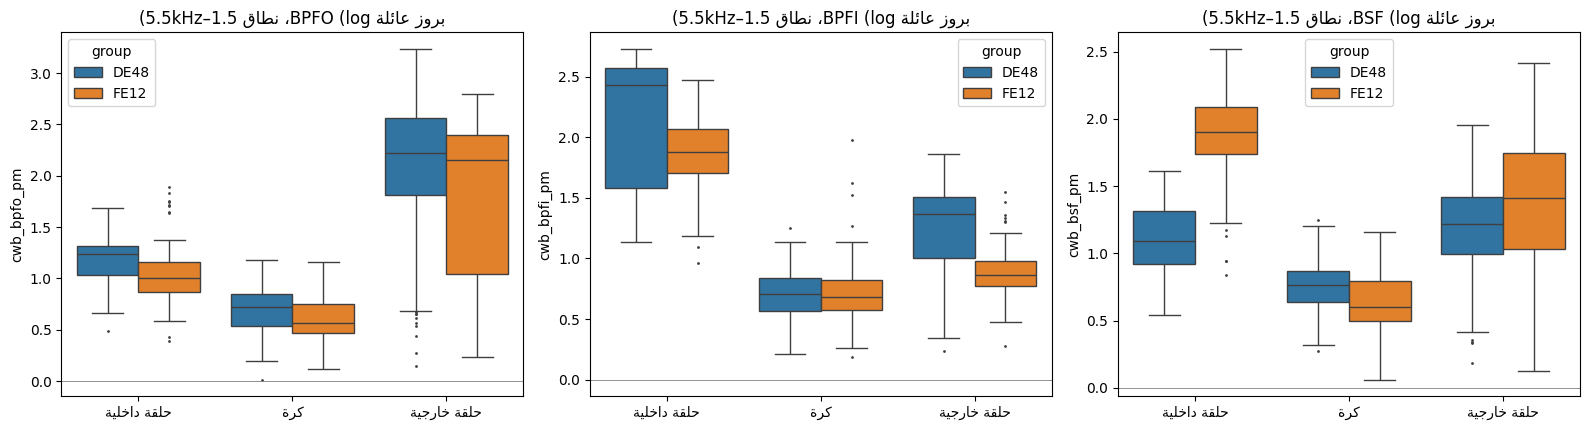

                 cwb_bpfo_pm  cwb_bpfi_pm  cwb_bsf_pm
side fault                                           
DE   ball               0.72         0.71        0.77
     inner_race         1.24         2.43        1.09
     outer_race         2.22         1.37        1.22
FE   ball               0.57         0.68        0.60
     inner_race         1.00         1.88        1.90
     outer_race         2.15         0.87        1.41


In [4]:
EDA = X.groupby(['group', 'fault']).agg(bearings=('bearing', 'nunique'), files=('file_num', 'nunique'), windows=('win_idx', 'size')).reset_index()
display(EDA)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
FA = {'ball': 'كرة', 'inner_race': 'حلقة داخلية', 'outer_race': 'حلقة خارجية'}
for ax, fam, ttl in zip(axes, ['bpfo', 'bpfi', 'bsf'], ['BPFO', 'BPFI', 'BSF']):
    sns.boxplot(data=X.assign(cls=X.fault.map(lambda s: ar(FA[s]))), x='cls', y=f'cwb_{fam}_pm', hue='group', ax=ax, fliersize=1)
    ax.set_title(ar(f'بروز عائلة {ttl} (log، نطاق 1.5–5.5kHz)')); ax.set_xlabel(''); ax.axhline(0, color='gray', lw=.6)
fig.tight_layout(); savefig(fig, 'f01_physics_features_by_class', 'بروز عائلات ترددات العطل حسب الفئة والجهة')
print(X.groupby(['side', 'fault'])[['cwb_bpfo_pm', 'cwb_bpfi_pm', 'cwb_bsf_pm']].median().round(2))

**تفسير:** عائلة BPFO أعلى بروزًا في الحلقة الخارجية، وBPFI في الداخلية، في **الجهتين**. وهذا الاتساق هو ما يجعل الخصائص قابلة للانتقال بين المحامل.
أما الكرة فبروز عائلاتها الثلاث منخفض عمومًا، أي أن بصمتها في طيف الغلاف ضعيفة، وهو ما سيظهر في تحليل الأخطاء.

## 9. التجميع حسب المحمل ومنع التسرب
نعرّف مولدات التقسيم الثلاثة، ونتحقق آليًا من أنه **لا محمل ولا ملف** يظهر في التدريب والاختبار معًا.
التعويض والتحجيم داخل الـ Pipeline، فيُتعلَّمان من محامل التدريب في كل طية.
ونختبر استقلال الصفوف: تغيير نوافذ اختبار أخرى لا يغيّر تنبؤ أي نافذة.

In [5]:
def splits_lobo26(df):
    return [(np.where(df.bearing.values != b)[0], np.where(df.bearing.values == b)[0]) for b in sorted(df.bearing.unique())]
def splits_bearing_balanced(df, seed, n=5):
    bt = df.drop_duplicates('bearing')[['bearing', 'fault']].reset_index(drop=True); out = []
    for _, te in StratifiedKFold(n_splits=n, shuffle=True, random_state=seed).split(bt, bt.fault):
        m = df.bearing.isin(set(bt.bearing.iloc[te])).values; out.append((np.where(~m)[0], np.where(m)[0]))
    return out
def splits_cross(df):
    return {f'{a}->{b}': (np.where(df.group.values == a)[0], np.where(df.group.values == b)[0]) for a, b in [('DE48', 'FE12'), ('FE12', 'DE48')]}
def disjoint(df, a, b):
    return not (set(df.bearing.iloc[a]) & set(df.bearing.iloc[b])) and not (set(df.file_num.iloc[a]) & set(df.file_num.iloc[b]))
_all = splits_lobo26(X) + [s for sd in range(5, 10) for s in splits_bearing_balanced(X, sd)] + list(splits_cross(X).values())
check('لا تداخل محامل/ملفات في كل تقسيمات التقييم (26 + 25 + 2)', all(disjoint(X, a, b) for a, b in _all), f'{len(_all)} تقسيمًا')
RF_FINAL = dict(n_estimators=300, min_samples_leaf=2, max_features=0.5, n_jobs=1, random_state=SEED)
RF_COMPARATOR = dict(n_estimators=300, min_samples_leaf=2, n_jobs=1, random_state=SEED)   # الإعداد السابق (max_features='sqrt' الافتراضي)
def make_rf(params):
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('clf', RandomForestClassifier(**params))])
def fit_predict(params, tr, te):
    m = make_rf(params).fit(tr[FEATS].values, LE.transform(tr.fault), clf__sample_weight=np.ones(len(tr)))
    return m.predict_proba(te[FEATS].values)
_a, _b = splits_lobo26(X)[0]; _m = make_rf(RF_FINAL).fit(X.iloc[_a][FEATS].values, LE.transform(X.iloc[_a].fault))
_te = X.iloc[_b][FEATS].values.copy(); _p1 = _m.predict_proba(_te[:3]); _te[3:] = _te[3:] * 1e3; _p2 = _m.predict_proba(_te)[:3]
check('استقلال الصفوف: تغيير نوافذ اختبار أخرى لا يغيّر التنبؤ', np.allclose(_p1, _p2))
check('معاملات التعويض والتحجيم = إحصاءات التدريب فقط', np.allclose(_m.named_steps['imp'].statistics_, np.nanmedian(X.iloc[_a][FEATS].values.astype(float), 0)) and
      np.allclose(_m.named_steps['sc'].mean_, X.iloc[_a][FEATS].values.astype(float).mean(0)))

PASS | لا تداخل محامل/ملفات في كل تقسيمات التقييم (26 + 25 + 2) | 53 تقسيمًا
PASS | استقلال الصفوف: تغيير نوافذ اختبار أخرى لا يغيّر التنبؤ | 
PASS | معاملات التعويض والتحجيم = إحصاءات التدريب فقط | 


## 10. التدريب واختيار النموذج
**الاختيار تمّ في مرحلة التطوير ولا يُعاد هنا.** هذا الدفتر لا يبحث عن نموذج أفضل، بل يعيد إنتاج النموذج المختار ويتحقق منه.
نعرض سجل قرار الاختيار من النتائج المحفوظة: تجارب بعامل واحد على البذور المتوازنة 0–4 وLOBO-26 وCross-End بقاعدة قبول محددة مسبقًا (+0.01)،
ثم تأكيد على بذور 5–9. **مقارنة LightGBM وCatBoost وSVM لم تُعَد بهذا البروتوكول المصحح**، فلا ندّعي تفوق RF عليها.

In [6]:
A4H = pd.read_csv(ART / 'A4_experiments_one_factor.csv')[['experiment', 'bb_file_f1_mean', 'lobo26_file_f1', 'cross_file_f1', 'delta_bb', 'accepted']]
display(A4H.round(4)); display(pd.read_csv(ART / 'A6_model_decision.csv'))
print('مصدر الجدولين: نتائج مرحلة التطوير المحفوظة (A4_experiments_one_factor.csv وA6_model_decision.csv). لم يُعد تشغيلهما هنا.')
t0 = time.time(); FINAL_MODEL = make_rf(RF_FINAL).fit(X[FEATS].values, LE.transform(X.fault), clf__sample_weight=np.ones(len(X)))
_ps = BUNDLE['model'].predict_proba(X[FEATS].values); _pf = FINAL_MODEL.predict_proba(X[FEATS].values)
check('إعادة التدريب على كل المحامل تعيد إنتاج تنبؤات النموذج المحفوظ v2 تمامًا', np.allclose(_ps, _pf), f'max|Δ|={np.abs(_ps - _pf).max():.2e} ({time.time() - t0:.0f} ث)')
check('النموذج المحفوظ: Pipeline بالخطوات imp ← sc ← clf وmax_features=0.5', [s for s, _ in BUNDLE['model'].steps] == ['imp', 'sc', 'clf']
      and BUNDLE['model'].named_steps['clf'].max_features == 0.5 and BUNDLE['model'].n_features_in_ == len(FEATS))

,experiment,bb_file_f1_mean,lobo26_file_f1,cross_file_f1,delta_bb,accepted
0,E0 الحالي (RF، C),0.8815,0.8735,0.8716,0.0000,False
1,E1 توافقيات غير متداخلة,0.8749,0.8647,0.8825,-0.0066,False
2,E2 + اندفاعية عديمة الأبعاد,0.8470,0.8477,0.8469,-0.0345,False
3,E3 أوزان الفئات,0.8838,0.8838,0.8815,0.0023,False
4,E4 أوزان المحمل×الفئة,0.8835,0.8939,0.8716,0.0020,False
5,E5 RF min_samples_leaf=5,0.8797,0.8735,0.8716,-0.0018,False
6,E6 RF max_features=0.5,0.8918,0.8930,0.8924,0.0103,True


,candidate,replaced,final,reason
0,E6 RF max_features=0.5,True,E6 RF max_features=0.5,تحسن مقبول في A4 وتأكد على البذور 5–9


مصدر الجدولين: نتائج مرحلة التطوير المحفوظة (A4_experiments_one_factor.csv وA6_model_decision.csv). لم يُعد تشغيلهما هنا.
PASS | إعادة التدريب على كل المحامل تعيد إنتاج تنبؤات النموذج المحفوظ v2 تمامًا | max|Δ|=0.00e+00 (4 ث)
PASS | النموذج المحفوظ: Pipeline بالخطوات imp ← sc ← clf وmax_features=0.5 | 


## 11. تقييم LOBO-26
26 طية: في كل طية يُدرَّب النموذج على 25 محملًا ويُختبر على المحمل المحجوب بكل تسجيلاته. ثم نحسب المقاييس على النوافذ والملفات والمحامل،
وفترة ثقة 95% بـ Bootstrap عنقودي (2000 سحبًا للمحامل مع الإرجاع).

In [7]:
def level_preds(df, P):
    t = pd.DataFrame(P, columns=CLASSES).assign(file=df.file_num.values, bearing=df.bearing.values, y=df.fault.values)
    out = {'window': (t.y.values, np.array(CLASSES)[P.argmax(1)])}
    for lvl in ['file', 'bearing']:
        g = t.groupby(lvl); pp = g[CLASSES].mean(); out[lvl] = (g.y.first().loc[pp.index].values, pp.idxmax(1).values)
    return out
def level_metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=CLASSES, zero_division=0)
    d = dict(n=len(y), macro_f1=f1_score(y, p, average='macro', labels=CLASSES, zero_division=0), balanced_acc=balanced_accuracy_score(y, p), accuracy=accuracy_score(y, p))
    for i, c in enumerate(CLASSES):
        d.update({f'P_{c}': pr[i], f'R_{c}': rc[i], f'F1_{c}': f1[i]})
    return d
def cluster_bootstrap(df, P, level='file', B=2000, seed=0):
    rng = np.random.default_rng(seed); bears = df.bearing.unique()
    t = pd.DataFrame(P, columns=CLASSES).assign(file=df.file_num.values, bearing=df.bearing.values, y=df.fault.values)
    agg = t.groupby('file' if level == 'file' else 'bearing').agg(bearing=('bearing', 'first'), y=('y', 'first'), **{c: (c, 'mean') for c in CLASSES})
    agg['pred'] = agg[CLASSES].idxmax(1); by_b = {b: agg[agg.bearing == b] for b in bears}; vals = []
    for _ in range(B):
        samp = pd.concat([by_b[b] for b in rng.choice(bears, size=len(bears), replace=True)])
        vals.append(f1_score(samp.y, samp.pred, average='macro', labels=CLASSES, zero_division=0))
    return np.percentile(vals, [2.5, 97.5])
def oof(params, splits):
    P = np.zeros((len(X), len(CLASSES)))
    for a, b in splits:
        P[b] = fit_predict(params, X.iloc[a], X.iloc[b])
    return P
t0 = time.time(); P_LOBO = oof(RF_FINAL, splits_lobo26(X))
LOBO = pd.DataFrame([dict(level=l, **level_metrics(*level_preds(X, P_LOBO)[l])) for l in ['window', 'file', 'bearing']])
CI_LOBO = {l: cluster_bootstrap(X, P_LOBO, l) for l in ['file', 'bearing']}
LOBO['ci95'] = LOBO.level.map(lambda l: f'[{CI_LOBO[l][0]:.3f}, {CI_LOBO[l][1]:.3f}]' if l in CI_LOBO else '—')
print(f'LOBO-26 خلال {time.time() - t0:.0f} ثانية'); display(LOBO.round(3))

LOBO-26 خلال 83 ثانية


,level,n,macro_f1,balanced_acc,accuracy,P_ball,R_ball,F1_ball,P_inner_race,R_inner_race,F1_inner_race,P_outer_race,R_outer_race,F1_outer_race,ci95
0,window,789,0.847,0.855,0.840,0.658,0.776,0.712,0.995,0.99,0.992,0.877,0.799,0.837,—
1,file,96,0.893,0.911,0.885,0.710,0.917,0.800,1.000,1.00,1.000,0.952,0.816,0.879,"[0.765, 0.984]"
2,bearing,26,0.927,0.952,0.923,0.750,1.000,0.857,1.000,1.00,1.000,1.000,0.857,0.923,"[0.805, 1.000]"


**تفسير:** المقياس الرئيسي (ملف) ومعه فترة الثقة. عرض الفترة (نحو ±0.1) يعكس قلة المحامل: خطأ في محمل واحد يغيّر النتيجة بوضوح.
وعلى مستوى المحمل يوجد 26 قرارًا فقط، فهو أكثر تذبذبًا.

## 12. تقييم Cross-End
تدريب على كل محامل جهة القيادة (6205، DE48) واختبار على كل محامل جهة المروحة (6203، FE12)، وبالعكس. النوع والأبعاد ومضاعفات الترددات والحساس كلها مختلفة.
هذا التقييم لم يدخل أي قرار اختيار.

In [8]:
CROSS_ROWS, P_CROSS = [], {}
for name, (a, b) in splits_cross(X).items():
    P = fit_predict(RF_FINAL, X.iloc[a], X.iloc[b]); P_CROSS[name] = (b, P); te = X.iloc[b]
    for l in ['window', 'file']:
        CROSS_ROWS.append(dict(direction=name, level=l, **level_metrics(*level_preds(te, P)[l])))
CROSS = pd.DataFrame(CROSS_ROWS); display(CROSS.round(3))
CROSS_FILE = CROSS[CROSS.level == 'file'].macro_f1.mean(); print(f'Cross-End Macro-F1 (ملف، متوسط الاتجاهين) = {CROSS_FILE:.4f}')

,direction,level,n,macro_f1,balanced_acc,accuracy,P_ball,R_ball,F1_ball,P_inner_race,R_inner_race,F1_inner_race,P_outer_race,R_outer_race,F1_outer_race
0,DE48->FE12,window,405,0.822,0.831,0.815,0.634,0.769,0.695,0.963,0.972,0.968,0.861,0.751,0.802
1,DE48->FE12,file,45,0.858,0.889,0.844,0.632,1.000,0.774,1.000,1.000,1.000,1.000,0.667,0.800
2,FE12->DE48,window,384,0.876,0.876,0.875,0.742,0.774,0.758,1.000,0.977,0.988,0.887,0.878,0.882
3,FE12->DE48,file,51,0.927,0.952,0.922,0.750,1.000,0.857,1.000,1.000,1.000,1.000,0.857,0.923


Cross-End Macro-F1 (ملف، متوسط الاتجاهين) = 0.8924


**تفسير:** النتيجة قريبة من LOBO-26 لأن الخصائص مبنية على ترددات العطل **مطبَّعة بسرعة الدوران وهندسة كل محمل**، وعلى بروز محلي لا يعتمد على كسب الحساس.
لكن Cross-End يجمع اتجاهين فقط، فهو تقدير واحد لا يحمل فترة ثقة موثوقة.

## 13. التقييم على بذور تقسيم متوازنة إضافية (5–9)
خمس طيات طبقية على جدول المحامل، فيكون عدد محامل كل فئة متوازنًا في كل طية، وذلك لخمس بذور لم تُستخدم في أي اختيار.
نقارن النموذج النهائي بالإعداد السابق (max_features الافتراضي) على **التقسيمات نفسها**.

In [9]:
t0 = time.time(); BB_ROWS = []; P_BB = {}
for sd in range(5, 10):
    sp = splits_bearing_balanced(X, sd)
    for tag, params in [('final (max_features=0.5)', RF_FINAL), ('comparator (max_features=sqrt)', RF_COMPARATOR)]:
        P = oof(params, sp); P_BB[(tag, sd)] = P
        BB_ROWS.append(dict(model=tag, seed=sd, **level_metrics(*level_preds(X, P)['file'])))
BB = pd.DataFrame(BB_ROWS)
BB_SUM = BB.groupby('model').agg(seeds=('seed', 'size'), file_macro_f1_mean=('macro_f1', 'mean'), file_macro_f1_sd=('macro_f1', lambda v: v.std(ddof=1)),
                                 R_ball=('R_ball', 'mean'), R_inner=('R_inner_race', 'mean'), R_outer=('R_outer_race', 'mean')).reset_index()
_pv = BB.pivot(index='seed', columns='model', values='macro_f1'); _diff = _pv['final (max_features=0.5)'] - _pv['comparator (max_features=sqrt)']
print(f'خلال {time.time() - t0:.0f} ثانية'); display(BB_SUM.round(4))
print(f'الفرق المقترن (نهائي − سابق) لكل بذرة: {np.round(_diff.values, 4)} | المتوسط {_diff.mean():+.4f}، والنهائي أفضل في {(_diff > 0).sum()}/5')

خلال 76 ثانية


,model,seeds,file_macro_f1_mean,file_macro_f1_sd,R_ball,R_inner,R_outer
0,comparator (max_features=sqrt),5,0.8974,0.0105,0.9833,0.9652,0.8082
1,final (max_features=0.5),5,0.9052,0.0125,0.9583,1.0000,0.8204


الفرق المقترن (نهائي − سابق) لكل بذرة: [0.0006 0.0107 0.0089 0.0095 0.0096] | المتوسط +0.0079، والنهائي أفضل في 5/5


**تفسير:** الفرق صغير (أقل من 0.01). اتجاهه متسق، لكنه أصغر بكثير من عرض فترة ثقة LOBO-26. لا نعدّ النموذج النهائي «أفضل بوضوح» من السابق،
بل اختيارًا مبررًا بقاعدة محددة مسبقًا. والانحراف المعياري هنا بين بذور التقسيم للمحامل نفسها.

## 14. المقاييس التفصيلية ومصفوفات الالتباس (LOBO-26)

precision                recall                    f1              
level        bearing   file window bearing   file window bearing   file window
cls                                                                           
ball            0.75  0.710  0.658   1.000  0.917  0.776   0.857  0.800  0.712
inner_race      1.00  1.000  0.995   1.000  1.000  0.990   1.000  1.000  0.992
outer_race      1.00  0.952  0.877   0.857  0.816  0.799   0.923  0.879  0.837

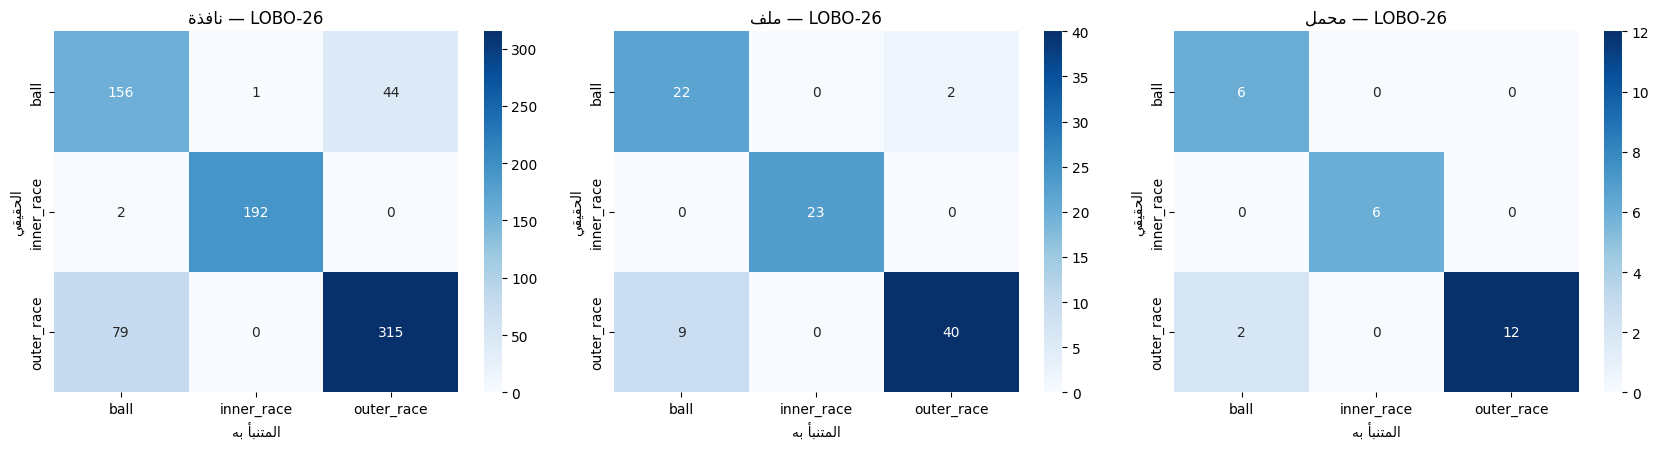

In [10]:
PER_CLASS = pd.DataFrame([dict(level=l, cls=c, precision=r[f'P_{c}'], recall=r[f'R_{c}'], f1=r[f'F1_{c}']) for l in ['window', 'file', 'bearing']
                          for r in [level_metrics(*level_preds(X, P_LOBO)[l])] for c in CLASSES]); display(PER_CLASS.pivot(index='cls', columns='level').round(3))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, l in zip(axes, ['window', 'file', 'bearing']):
    y, p = level_preds(X, P_LOBO)[l]
    sns.heatmap(confusion_matrix(y, p, labels=CLASSES), annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(ar({'window': 'نافذة', 'file': 'ملف', 'bearing': 'محمل'}[l]) + ' — LOBO-26'); ax.set_xlabel(ar('المتنبأ به')); ax.set_ylabel(ar('الحقيقي'))
fig.tight_layout(); savefig(fig, 'f02_confusion_lobo26', 'مصفوفات الالتباس على مستويات النافذة والملف والمحمل (LOBO-26، النموذج النهائي)')

## 15. تحليل الأخطاء: الحلقة الخارجية
**BPFO** (Ball Pass Frequency, Outer race) هو معدل مرور العناصر الدوارة فوق عيب ثابت في الحلقة الخارجية:
BPFO = (N/2)·fr·(1 − d/D·cos φ). يظهر قمةً وتوافقيات في طيف الغلاف عندما تولّد الاصطدامات نبضات منتظمة.
إذا كانت القمة ضعيفة أو غائبة فلا يجد المصنف الدليل الرئيسي على عطل الحلقة الخارجية، فيميل إلى الكرة، وهي الفئة ذات البصمة الأضعف في البيانات.

نجمع أخطاء Outer → Ball على مستوى الملف من 6 تقييمات خارج الطية للنموذج النهائي (LOBO-26 وبذور 5–9)، ثم نقارن بروز BPFO:
على النوافذ، وعلى **التسجيل الكامل** (دقة ترددية أعلى).

In [11]:
_evals = {'LOBO-26': P_LOBO, **{f'bb seed {sd}': P_BB[('final (max_features=0.5)', sd)] for sd in range(5, 10)}}
FT = []
for tag, P in _evals.items():
    t = pd.DataFrame(P, columns=CLASSES).assign(file_num=X.file_num.values, y=X.fault.values)
    f = t.groupby('file_num').agg(y=('y', 'first'), **{c: (c, 'mean') for c in CLASSES}); f['pred'] = f[CLASSES].idxmax(1); f['eval'] = tag; FT.append(f.reset_index())
FT = pd.concat(FT)
OR = FT[FT.y == 'outer_race'].groupby('file_num').agg(evals=('pred', 'size'), as_ball=('pred', lambda s: (s == 'ball').sum()), mean_P_ball=('ball', 'mean'),
                                                      mean_P_outer=('outer_race', 'mean')).join(FILES.set_index('file_num')[['bearing', 'load_hp', 'rpm_used']])
OR = OR.join(X.groupby('file_num')[['cwb_bpfo_pm', 'cwb_bsf_pm', 'cwb_bpfi_pm']].mean())
WRONG = set(OR[OR.as_ball > OR.evals / 2].index)
OR_ERR = OR[OR.as_ball > 0].sort_values(['as_ball', 'mean_P_ball'], ascending=False); display(OR_ERR.round(3))
def full_ses(f):
    r = FILES.set_index('file_num').loc[f]; d = ses_feats(SIG12[f].astype(np.float64), r.side, r.rpm_used, 'full', FIXED_SOS)
    return dict(file_num=f, full_bpfo_pm=d['full_bpfo_pm'], full_bsf_pm=d['full_bsf_pm'], full_bpfi_pm=d['full_bpfi_pm'])
FULL = pd.DataFrame([full_ses(f) for f in FILES[FILES.fault.isin(['outer_race', 'ball'])].file_num]).set_index('file_num').join(FILES.set_index('file_num')[['fault', 'bearing']])
FULL['status'] = np.where(FULL.fault == 'ball', 'ball', np.where(FULL.index.isin(WRONG), 'outer: wrong (→ball)', 'outer: correct'))
CMP = FULL.groupby('status')[['full_bpfo_pm', 'full_bsf_pm']].median().join(
    X.assign(status=np.where(X.fault == 'ball', 'ball', np.where(X.file_num.isin(WRONG), 'outer: wrong (→ball)', 'outer: correct')))
     [X.fault.isin(['ball', 'outer_race'])].groupby('status')[['cwb_bpfo_pm']].median().rename(columns={'cwb_bpfo_pm': 'window_bpfo_pm'}))
CMP['files'] = FULL.status.value_counts(); display(CMP.round(2))
print('محامل الملفات الخاطئة:', FILES.set_index('file_num').loc[sorted(WRONG)].bearing.value_counts().to_dict())

,evals,as_ball,mean_P_ball,mean_P_outer,bearing,load_hp,rpm_used,cwb_bpfo_pm,cwb_bsf_pm,cwb_bpfi_pm
file_num,,,,,,,,,,
201,6,6,0.911,0.089,DE48|outer_race|0.014|@6,0,1796.0,0.556,0.665,0.646
202,6,6,0.849,0.149,DE48|outer_race|0.014|@6,1,1772.0,0.638,0.576,0.749
203,6,6,0.783,0.214,DE48|outer_race|0.014|@6,2,1749.0,0.806,0.651,0.753
204,6,6,0.771,0.226,DE48|outer_race|0.014|@6,3,1723.0,0.781,0.771,0.800
306,6,6,0.675,0.308,FE12|outer_race|0.007|@12,2,1755.0,0.765,0.619,0.859
302,6,6,0.674,0.305,FE12|outer_race|0.007|@12,0,1797.0,0.715,0.674,0.746
307,6,6,0.658,0.334,FE12|outer_race|0.007|@12,3,1733.0,0.836,0.805,0.830
305,6,6,0.614,0.341,FE12|outer_race|0.007|@12,1,1775.0,0.651,0.724,0.827
301,6,4,0.545,0.446,FE12|outer_race|0.007|@3,3,1733.0,0.939,0.953,0.821


,full_bpfo_pm,full_bsf_pm,window_bpfo_pm,files
status,,,,
ball,0.89,0.98,0.62,24
outer: correct,3.02,1.90,2.32,40
outer: wrong (→ball),0.87,0.89,0.76,9


محامل الملفات الخاطئة: {'DE48|outer_race|0.014|@6': 4, 'FE12|outer_race|0.007|@12': 4, 'FE12|outer_race|0.007|@3': 1}


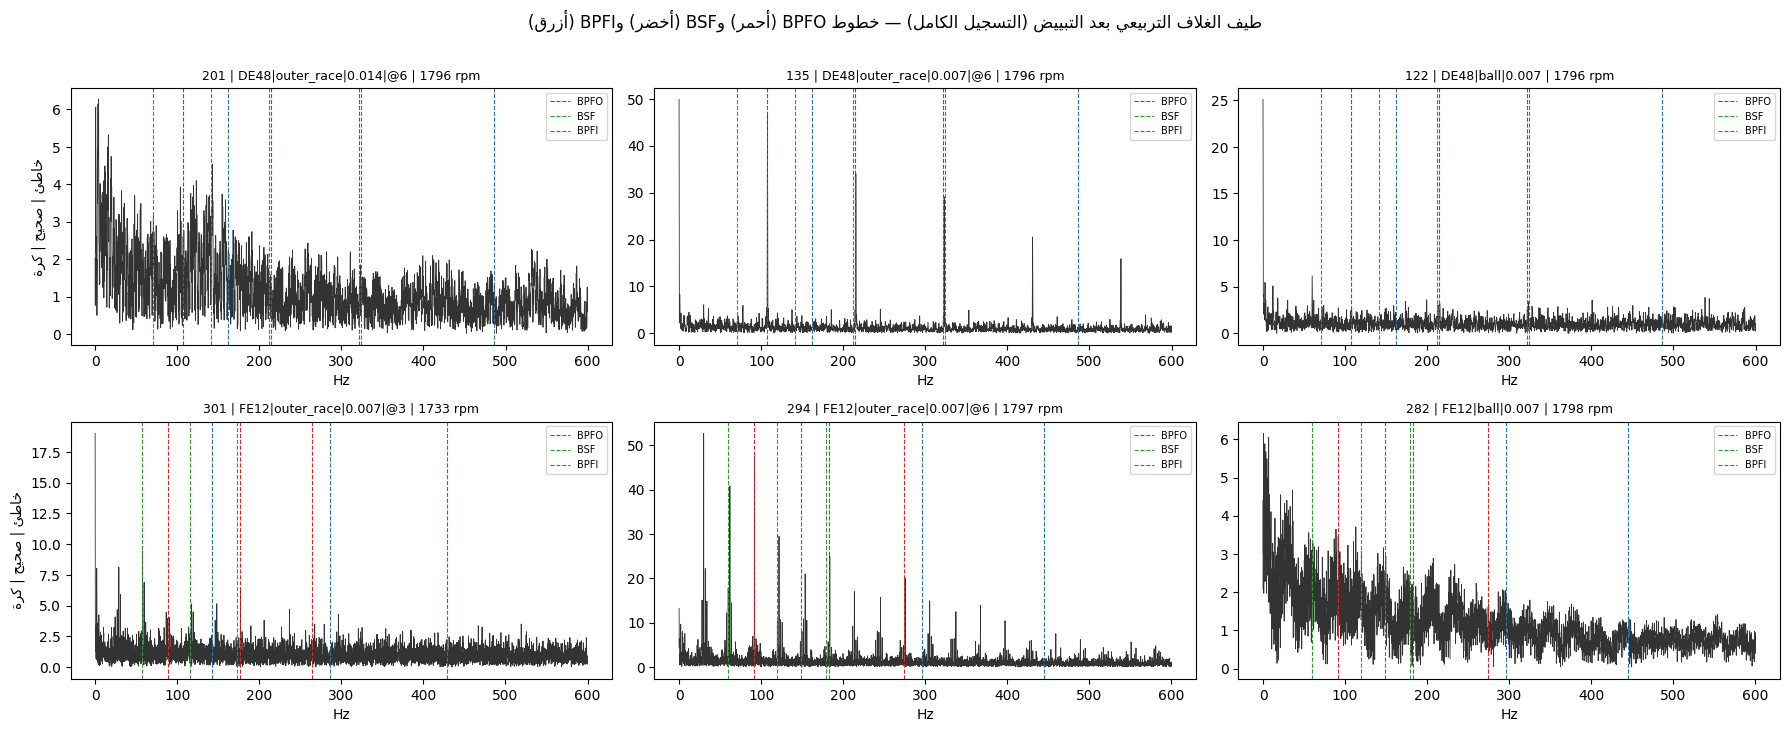

In [12]:
def plot_ses(ax, f):
    r = FILES.set_index('file_num').loc[f]; xw = signal.sosfiltfilt(FIXED_SOS, cpw(SIG12[f].astype(np.float64)))
    e2 = np.abs(signal.hilbert(xw)) ** 2; e2 -= e2.mean(); nfft = int(2 ** np.ceil(np.log2(len(e2))))
    E = np.abs(np.fft.rfft(e2 * np.hanning(len(e2)), nfft)); ef = np.fft.rfftfreq(nfft, 1 / FS); m = ef < 600
    ax.plot(ef[m], E[m] / np.median(E[m]), lw=.6, color='#333'); fr = r.rpm_used / 60; b = BEAR[r.side]
    for fam, col in [('bpfo', 'tab:red'), ('bsf', 'tab:green'), ('bpfi', 'tab:blue')]:
        for k in range(1, 4):
            ax.axvline(k * b[fam] * fr, color=col, ls='--', lw=.8, label=fam.upper() if k == 1 else None)
    ax.set_title(f'{f} | {r.bearing} | {r.rpm_used:.0f} rpm', fontsize=9); ax.set_xlabel('Hz'); ax.legend(fontsize=7)
_ex = []
for g in ['DE48', 'FE12']:
    w = sorted(f for f in WRONG if FILES.set_index('file_num').loc[f, 'group'] == g)
    c = sorted(f for f in OR.index if f not in WRONG and FILES.set_index('file_num').loc[f, 'group'] == g)
    bl = sorted(FILES[(FILES.group == g) & (FILES.fault == 'ball')].file_num)
    if w:
        _ex.append((w[0], c[0], bl[0]))
if _ex:
    fig, axes = plt.subplots(len(_ex), 3, figsize=(18, 3.6 * len(_ex)), squeeze=False)
    for i, trio in enumerate(_ex):
        for j, f in enumerate(trio):
            plot_ses(axes[i, j], f)
        axes[i, 0].set_ylabel(ar('خاطئ | صحيح | كرة'))
    fig.suptitle(ar('طيف الغلاف التربيعي بعد التبييض (التسجيل الكامل) — خطوط BPFO (أحمر) وBSF (أخضر) وBPFI (أزرق)'), y=1.01); fig.tight_layout()
    savefig(fig, 'f03_ses_outer_wrong_vs_correct', 'طيف الغلاف: ملف Outer خاطئ، وملف Outer صحيح، وملف كرة من الجهة نفسها')

**تفسير وحدود الاستنتاج:**
- ملفات Outer التي صُنّفت كرة في أغلب التقييمات تقع في عدد قليل من المحامل. بروز BPFO فيها قريب من مستوى الكرة، وبعيد عن ملفات Outer الصحيحة، على النوافذ وعلى التسجيل الكامل.
- هذا **تفسير معقول ومدعوم بالقياس**: المصنف يفقد دليله الأساسي حين لا تظهر قمة BPFO. لكنه **ليس إثباتًا لسبب فيزيائي عام**.
  غياب القمة قد يعود إلى حالة العيب نفسه، أو موضع الحساس، أو نقل الاهتزاز، أو جودة التسجيل، ولا تسمح البيانات بالتمييز بين هذه الاحتمالات.
- تداخل نوافذ بعض التوافقيات بين العائلات (2×BPFO مع 3×BSF) لا يفسر هذه الأخطاء، فالملفات الخاطئة بلا قمة BPFO أصلًا. وتجربة إزالته في مرحلة التطوير لم تحسّن النتيجة.

## 16. اكتشاف الأعطال الجديدة ومعايرة العتبة
**السياق:** نحجب فئة عطل كاملة عن التدريب ونختبر هل تُكتشف ملفاتها بوصفها «غير مألوفة». **لا توجد فئة سليمة**، فهذا ليس تحققًا من الفصل بين سليم ومعطوب.

**البروتوكول (بذور 100–104، ولكل فئة محجوبة):** المحامل المعروفة تُقسم على مستوى المحمل إلى اختبار (ربعها)، ومن الباقي معايرة (ربعها) وتدريب.
كل محامل الفئة المحجوبة غير معروفة. **العتبة من ملفات المعايرة فقط.**

**Physics-Residual:** بروز أقوى عائلة تردد في الإشارة − بروز أقوى عائلة من العائلات المعروفة. لا تُدرَّب ولا تستخدم أي تسمية للفئة المجهولة.
نقارنها بـ kNN (المسافة في فضاء الخصائص) وMSP (ثقة مصنف LightGBM).

**العتبات:**
- **الهدف α = 5% بقاعدة conformal** (الدرجة رقم ⌈(n+1)(1−α)⌉). تحتاج 19 ملف معايرة على الأقل، وإلا كانت العتبة ∞.
- **أعلى درجة معايرة**، وهي أصغر α يمكن طلبه بعدد n من الملفات (α ≈ 1/(n+1)).

خلال 3 ثانية


,method,unknown,splits,median_cal_files,conformal_5pct_feasible_share,target_FPR,achievable_alpha_median,observed_FPR,FPR_CI95,recall,recall_CI95,file_AUROC_mean,file_AUROC_sd,known_test_files,unknown_files
0,MSP,all,15,13.0,0.0,0.05,0.071,0.126,"[0.087, 0.174]",0.262,"[0.224, 0.304]",0.670,0.196,246,480
1,MSP,ball,5,15.0,0.0,0.05,0.062,0.129,"[0.068, 0.215]",0.167,"[0.105, 0.246]",0.618,0.124,93,120
2,MSP,inner_race,5,15.0,0.0,0.05,0.062,0.074,"[0.030, 0.146]",0.383,"[0.294, 0.478]",0.814,0.079,95,115
3,MSP,outer_race,5,12.0,0.0,0.05,0.077,0.207,"[0.112, 0.334]",0.253,"[0.200, 0.312]",0.579,0.269,58,245
4,PhysicsResidual,all,15,13.0,0.0,0.05,0.071,0.061,"[0.035, 0.099]",0.552,"[0.506, 0.597]",0.878,0.076,246,480
5,PhysicsResidual,ball,5,15.0,0.0,0.05,0.062,0.043,"[0.012, 0.106]",0.142,"[0.085, 0.217]",0.830,0.072,93,120
6,PhysicsResidual,inner_race,5,15.0,0.0,0.05,0.062,0.105,"[0.052, 0.185]",0.548,"[0.452, 0.641]",0.841,0.033,95,115
7,PhysicsResidual,outer_race,5,12.0,0.0,0.05,0.077,0.017,"[0.000, 0.092]",0.755,"[0.696, 0.808]",0.962,0.014,58,245
8,kNN,all,15,13.0,0.0,0.05,0.071,0.138,"[0.098, 0.188]",0.633,"[0.588, 0.677]",0.655,0.387,246,480
9,kNN,ball,5,15.0,0.0,0.05,0.062,0.194,"[0.119, 0.289]",0.008,"[0.000, 0.046]",0.145,0.127,93,120


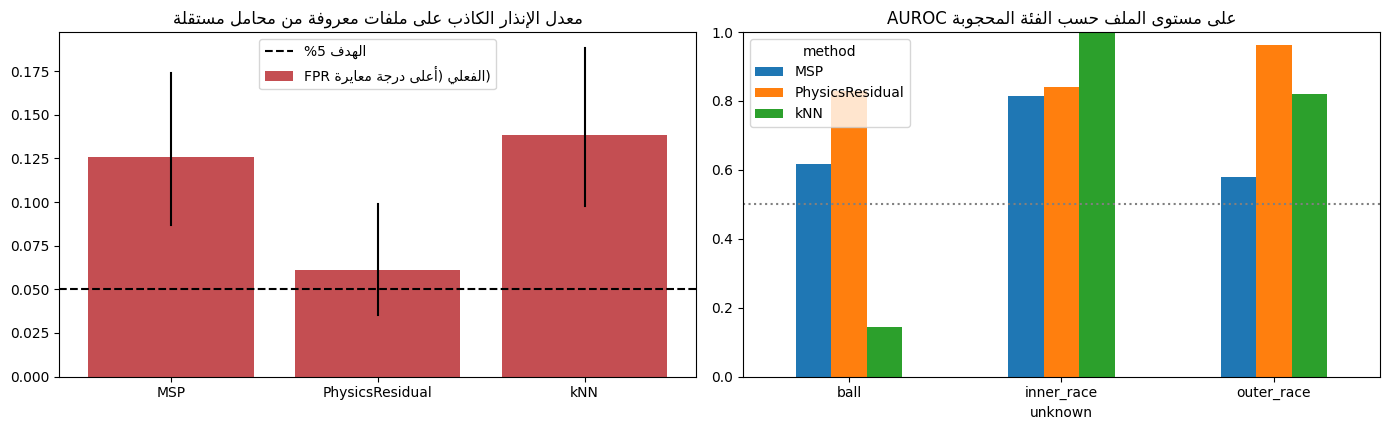

In [13]:
from scipy.stats import beta as _beta
FAM_OF = {'inner_race': 'bpfi', 'ball': 'bsf', 'outer_race': 'bpfo'}
def phys_residual(d, known):
    allv = np.stack([d[f'cwb_{f}_pm'].values for f in ['bpfo', 'bpfi', 'bsf']], 1); kv = np.stack([d[f'cwb_{FAM_OF[c]}_pm'].values for c in known], 1)
    return allv.max(1) - kv.max(1)
def cp_ci(k, n, a=0.05):
    return (_beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0, _beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0)
def novelty_split(unk, seed, alpha=0.05):
    known_cls = [c for c in CLASSES if c != unk]
    kb = X[X.fault != unk].drop_duplicates('bearing')[['bearing', 'fault']].reset_index(drop=True)
    _, te_i = next(StratifiedKFold(n_splits=4, shuffle=True, random_state=seed).split(kb, kb.fault)); te_b = set(kb.bearing.iloc[te_i])
    pb = kb[~kb.bearing.isin(te_b)].reset_index(drop=True)
    _, ca_i = next(StratifiedKFold(n_splits=4, shuffle=True, random_state=seed + 1).split(pb, pb.fault)); ca_b = set(pb.bearing.iloc[ca_i])
    fit = X[X.bearing.isin(set(pb.bearing) - ca_b)]; cal = X[X.bearing.isin(ca_b)]; tst = X[X.bearing.isin(te_b)]; unkn = X[X.fault == unk]
    assert not (set(fit.bearing) & ca_b) and not (set(fit.bearing) & te_b) and not (ca_b & te_b) and unk not in set(fit.fault) | set(cal.fault)
    imp = SimpleImputer(strategy='median').fit(fit[FEATS]); sc = StandardScaler().fit(imp.transform(fit[FEATS])); nn = NearestNeighbors(n_neighbors=10).fit(sc.transform(imp.transform(fit[FEATS])))
    clf = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
                    ('clf', LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                           random_state=SEED, n_jobs=1, verbose=-1))]).fit(fit[FEATS].values, LE.transform(fit.fault))
    def scores(d):
        Z = sc.transform(imp.transform(d[FEATS])); return dict(PhysicsResidual=phys_residual(d, known_cls), kNN=nn.kneighbors(Z)[0].mean(1), MSP=1 - clf.predict_proba(d[FEATS].values).max(1))
    S = {k: scores(d) for k, d in [('cal', cal), ('tst', tst), ('unk', unkn)]}; rows = []
    for m in ['PhysicsResidual', 'kNN', 'MSP']:
        fm = {k: pd.Series(S[k][m]).groupby(d.file_num.values).mean() for k, d in [('cal', cal), ('tst', tst), ('unk', unkn)]}
        s = np.sort(fm['cal'].values); n = len(s); kk = int(np.ceil((n + 1) * (1 - alpha))); thr_c = s[kk - 1] if kk <= n else np.inf; thr_m = s[-1]
        yt = np.r_[np.zeros(len(fm['tst'])), np.ones(len(fm['unk']))]; st = np.r_[fm['tst'].values, fm['unk'].values]
        rows.append(dict(unknown=unk, seed=seed, method=m, cal_files=n, cal_sufficient=kk <= n, known_test_files=len(fm['tst']), unknown_files=len(fm['unk']),
                         fp_conformal=int((fm['tst'] > thr_c).sum()), tp_conformal=int((fm['unk'] > thr_c).sum()),
                         fp_maxcal=int((fm['tst'] > thr_m).sum()), tp_maxcal=int((fm['unk'] > thr_m).sum()), alpha_achievable=1 / (n + 1), file_AUROC=roc_auc_score(yt, st)))
    return rows
t0 = time.time(); NOV_RAW = pd.DataFrame([r for u in CLASSES for sd in range(100, 105) for r in novelty_split(u, sd)])
def nov_summary(df):
    out = []
    for m, d in df.groupby('method'):
        for scope, dd in [('all', d)] + [(u, d[d.unknown == u]) for u in CLASSES]:
            nk, nu = dd.known_test_files.sum(), dd.unknown_files.sum(); fp, tp = dd.fp_maxcal.sum(), dd.tp_maxcal.sum()
            out.append(dict(method=m, unknown=scope, splits=len(dd), median_cal_files=dd.cal_files.median(), conformal_5pct_feasible_share=dd.cal_sufficient.mean(),
                            target_FPR=0.05, achievable_alpha_median=dd.alpha_achievable.median(),
                            observed_FPR=fp / nk, FPR_CI95='[{:.3f}, {:.3f}]'.format(*cp_ci(fp, nk)), recall=tp / nu, recall_CI95='[{:.3f}, {:.3f}]'.format(*cp_ci(tp, nu)),
                            file_AUROC_mean=dd.file_AUROC.mean(), file_AUROC_sd=dd.file_AUROC.std(ddof=1), known_test_files=nk, unknown_files=nu))
    return pd.DataFrame(out)
NOV = nov_summary(NOV_RAW); print(f'خلال {time.time() - t0:.0f} ثانية'); display(NOV.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
_s = NOV[NOV.unknown == 'all'].set_index('method')
axes[0].bar(_s.index, _s.observed_FPR, color='#C44E52', label=ar('FPR الفعلي (أعلى درجة معايرة)')); axes[0].axhline(0.05, color='k', ls='--', label=ar('الهدف 5%'))
for i, (m, r) in enumerate(_s.iterrows()):
    lo, hi = [float(v) for v in r.FPR_CI95.strip('[]').split(',')]; axes[0].plot([i, i], [lo, hi], color='k')
axes[0].legend(); axes[0].set_title(ar('معدل الإنذار الكاذب على ملفات معروفة من محامل مستقلة'))
NOV[NOV.unknown != 'all'].pivot(index='unknown', columns='method', values='file_AUROC_mean').plot.bar(ax=axes[1], rot=0); axes[1].set_ylim(0, 1); axes[1].axhline(.5, color='gray', ls=':')
axes[1].set_title(ar('AUROC على مستوى الملف حسب الفئة المحجوبة')); fig.tight_layout(); savefig(fig, 'f04_novelty', 'اكتشاف الجديد: FPR الفعلي وAUROC (بذور 100–104)')

**تفسير صادق:**
- **الهدف 5% غير قابل للضمان بهذه البيانات.** وسيط ملفات المعايرة أقل من 19، فقاعدة conformal عند 5% غير ممكنة في كل التقسيمات (العتبة = ∞، فلا اكتشاف).
- بعتبة «أعلى درجة معايرة» (α ممكن ≈ 7%) يظهر **FPR فعلي** وفترة Clopper-Pearson. الفترة تقريبية، لأن ملفات المحمل الواحد مترابطة.
  **FPR مُقاس قرب 6% لا يضمن 5% ولا 6% في التشغيل المستقبلي:** المعايرة صغيرة، والمحامل الجديدة قد تختلف توزيعيًا.
- AUROC يقيس قدرة الترتيب بمعزل عن العتبة، وRecall يتبع العتبة المختارة. Physics-Residual أفضل الثلاث وأكثرها توازنًا بين الفئات.
  أما kNN فينعكس مع الكرة، لأن إشارتها الضعيفة تقع داخل منطقة المعروف.
- **ملاحظة منهجية:** Physics-Residual صُممت في مرحلة التطوير بعد رؤية نتائج تقسيم سابق (بذرة 42). نتائجها هنا على تقسيمات جديدة، لكن على المحامل نفسها.

## 17. نتائج التعلم النشط (من النتائج المحفوظة)
**لم يُعَد تشغيل التعلم النشط في هذا الدفتر.** نعرض النتيجة المحفوظة من مرحلة التطوير (`09_active_learning_unseen_bearings.csv`):
- النموذج: LightGBM على الخصائص C ونوافذ 2 ثانية، وتحقق ثابت على 7 محامل غير مرئية، و10 تكرارات، وميزانية 24 ملفًا.
- هذه النتيجة **ليست للنموذج النهائي RF**.

In [14]:
AL = pd.read_csv(ART / '09_active_learning_unseen_bearings.csv'); display(AL.round(3))
print('التمثيل old = خصائص الدفتر الأول بنوافذ 0.17 ثانية؛ new = الخصائص C بنوافذ 2 ثانية.')

,rep,strategy,AULC_file_f1,AULC_sd,final_file_f1,final_window_f1,bearings_labeled_at_24,win_rate_vs_random,wilcoxon_p,full_pool_file_f1
0,old,random,0.374,0.072,0.455,0.436,14.8,NaN,NaN,0.304
1,old,uncertainty,0.405,0.068,0.528,0.517,14.6,0.6,0.232,0.304
2,new,anomaly,0.728,0.108,0.806,0.814,13.2,0.7,0.160,0.894
3,new,bearing_unc,0.722,0.056,0.761,0.787,19.0,0.7,0.193,0.894
4,new,hybrid,0.726,0.054,0.831,0.804,14.1,0.7,0.322,0.894
5,new,random,0.681,0.080,0.866,0.824,14.8,NaN,NaN,0.894
6,new,uncertainty,0.696,0.082,0.814,0.800,12.2,0.7,0.557,0.894


التمثيل old = خصائص الدفتر الأول بنوافذ 0.17 ثانية؛ new = الخصائص C بنوافذ 2 ثانية.


**تفسير:** العامل الحاسم في تقليل تكلفة التوسيم هو **التمثيل الفيزيائي** (المساحة تحت المنحنى ارتفعت كثيرًا بين old وnew)، لا استراتيجية الاختيار.
فلم تتفوق أي استراتيجية على الاختيار العشوائي تفوقًا دالًا (انظر wilcoxon_p).

## 18. تحميل النموذج النهائي والاستدلال
دالة استدلال كاملة من الإشارة الخام: تخفيض التردد، ثم النوافذ، ثم الخصائص، ثم **التحقق من أسماء الخصائص وترتيبها**، ثم التنبؤ.
القيم المفقودة يعوضها وسيط التدريب داخل الـ Pipeline، والقيم اللانهائية أو الأعمدة الناقصة تُرفض برسالة واضحة.
المثال يستخدم ملفًا من البيانات **سبق أن تدرّب عليه النموذج النهائي**، فهو عرض لآلية الاستدلال لا تقييم. التقييم في الأقسام 11–13.

In [15]:
MODEL = joblib.load(MODEL_PATH)
def validate_features(df, required):
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f'خصائص ناقصة ({len(missing)}): {missing[:5]}...')
    Z = df[required].apply(pd.to_numeric, errors='coerce')
    if np.isinf(Z.values).any():
        raise ValueError('قيم لانهائية في المدخلات')
    if Z.isna().any().any():
        print(f'تنبيه: {int(Z.isna().sum().sum())} قيمة مفقودة ستُعوَّض بوسيط التدريب')
    return Z.values
def predict_recording(x, fs, side, rpm, bundle=MODEL):
    """x: إشارة جهة العطل الخام، وfs: ترددها، وside: 'DE' أو 'FE'، وrpm: سرعة الدوران المقاسة."""
    x = to_12k(np.asarray(x, dtype=np.float64), fs); x = (x - x.mean()).astype(np.float32).astype(np.float64)
    n = max(1, min((len(x) - WIN) // HOP + 1, MAXW)); rows = []
    for k in range(n):
        seg = x[k * HOP:k * HOP + WIN]
        if len(seg) < WIN:
            break
        d = ses_feats(seg, side, rpm, 'cw'); d.update(ses_feats(seg, side, rpm, 'cwb', FIXED_SOS)); rows.append(d)
    if not rows:
        raise ValueError('التسجيل أقصر من نافذة واحدة (2 ثانية)')
    F = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan)
    P = bundle['model'].predict_proba(validate_features(F, bundle['features']))
    return pd.Series(P.mean(0), index=bundle['classes']), P
_demo = FILES[FILES.fault == 'outer_race'].iloc[0]
_rec = read_mat(DATA_DIR / f'{_demo.file_num}.mat', _demo.file_num)
probs, P_win = predict_recording(_rec[_demo.side], _demo.fs_hz, _demo.side, _demo.rpm_used)
print(f'ملف {_demo.file_num} ({_demo.bearing}) | الحقيقي: {_demo.fault} | المتنبأ به: {probs.idxmax()} | نوافذ: {len(P_win)}'); display(probs.round(3).to_frame('probability'))
_ref = X[X.file_num == _demo.file_num]
check('الاستدلال من الملف الخام يطابق الخصائص المحسوبة في الدفتر', np.allclose(P_win, MODEL['model'].predict_proba(_ref[FEATS].values)))
try:
    validate_features(_ref.drop(columns=[FEATS[0]]), MODEL['features']); _okm = False
except ValueError as e:
    print('مثال إدخال ناقص →', e); _okm = True
check('رفض المدخلات التي تنقصها خصائص برسالة واضحة', _okm)
_bad = _ref.copy(); _bad.loc[_bad.index[0], FEATS[0]] = np.nan
check('قيمة مفقودة تُعوَّض دون خطأ', np.isfinite(MODEL['model'].predict_proba(validate_features(_bad, FEATS))).all())

ملف 135 (DE48|outer_race|0.007|@6) | الحقيقي: outer_race | المتنبأ به: outer_race | نوافذ: 4


,probability
ball,0.0
inner_race,0.0
outer_race,1.0


PASS | الاستدلال من الملف الخام يطابق الخصائص المحسوبة في الدفتر | 
مثال إدخال ناقص → خصائص ناقصة (1): ['cw_bpfo_p1']...
PASS | رفض المدخلات التي تنقصها خصائص برسالة واضحة | 
تنبيه: 1 قيمة مفقودة ستُعوَّض بوسيط التدريب
PASS | قيمة مفقودة تُعوَّض دون خطأ | 


## 19. الحدود، وقابلية إعادة الإنتاج، والعمل المستقبلي
### 19.1 قابلية إعادة الإنتاج: التحقق من النتائج مقابل النتائج المحفوظة
كل رقم نهائي أعلاه أُعيد حسابه في هذا الدفتر. هنا نقارنه بالقيم المحفوظة من مرحلة التطوير، وأي فرق يظهر صراحة.

In [16]:
_A7 = pd.read_csv(ART / 'A7_final_model_summary.csv').iloc[0]; _A6 = pd.read_csv(ART / 'A6_confirmation_seeds_5_9.csv').set_index('experiment')
_A5 = pd.read_csv(ART / 'A5_novelty_summary.csv'); _A5p = _A5[(_A5.method == 'PhysicsResidual') & (_A5.unknown == _A5.unknown.iloc[0])].iloc[0]
_lf = LOBO.set_index('level'); _ns = NOV[(NOV.method == 'PhysicsResidual') & (NOV.unknown == 'all')].iloc[0]; _bb = BB_SUM.set_index('model')
VER = pd.DataFrame([
    ('LOBO-26 Macro-F1 (ملف)', 'LOBO-26، 26 طية، النموذج النهائي', _lf.loc['file', 'macro_f1'], _A7.lobo26_file_f1),
    ('LOBO-26 فترة 95% (ملف) — الحد الأدنى', 'Bootstrap عنقودي، 2000، بذرة 0', CI_LOBO['file'][0], float(_A7.ci_file.strip('[]').split(',')[0])),
    ('LOBO-26 فترة 95% (ملف) — الحد الأعلى', 'Bootstrap عنقودي، 2000، بذرة 0', CI_LOBO['file'][1], float(_A7.ci_file.strip('[]').split(',')[1])),
    ('LOBO-26 Macro-F1 (محمل)', 'LOBO-26', _lf.loc['bearing', 'macro_f1'], _A7.lobo26_bearing_f1),
    ('Cross-End Macro-F1 (ملف)', 'DE→FE وFE→DE، متوسط', CROSS_FILE, _A7.cross_file_f1),
    ('بذور متوازنة 5–9 — النهائي', '5 بذور × 5 طيات (محامل)', _bb.loc['final (max_features=0.5)', 'file_macro_f1_mean'], _A6.loc[[i for i in _A6.index if 'E6' in i][0], 'bb_file_f1_mean']),
    ('بذور متوازنة 5–9 — السابق', '5 بذور × 5 طيات (محامل)', _bb.loc['comparator (max_features=sqrt)', 'file_macro_f1_mean'], _A6.loc[[i for i in _A6.index if 'E0' in i][0], 'bb_file_f1_mean']),
    ('Novelty AUROC ملف (Physics-Residual)', '3 فئات × بذور 100–104', _ns.file_AUROC_mean, _A5p.file_AUROC_mean),
    ('Novelty FPR فعلي (أعلى درجة معايرة)', f'{int(_ns.known_test_files)} ملفًا معروفًا من محامل مستقلة', _ns.observed_FPR, _A5p.FPR_max_rule),
    ('Novelty Recall (أعلى درجة معايرة)', f'{int(_ns.unknown_files)} ملفًا من الفئات المحجوبة', _ns.recall, _A5p.recall_max_rule),
], columns=['metric', 'protocol', 'final_notebook', 'saved_artifact'])
VER['abs_diff'] = (VER.final_notebook - VER.saved_artifact).abs(); VER['match'] = VER.abs_diff < 1e-3
display(VER.round(4)); VER.to_csv(OUT_R / 'final_metric_verification.csv', index=False, encoding='utf-8-sig')
check('كل المقاييس النهائية المعاد حسابها تطابق النتائج المحفوظة (|Δ| < 0.001)', VER.match.all(), f'{int(VER.match.sum())}/{len(VER)}')

,metric,protocol,final_notebook,saved_artifact,abs_diff,match
0,LOBO-26 Macro-F1 (ملف),LOBO-26، 26 طية، النموذج النهائي,0.8930,0.8930,0.0000,True
1,LOBO-26 فترة 95% (ملف) — الحد الأدنى,Bootstrap عنقودي، 2000، بذرة 0,0.7654,0.7650,0.0004,True
2,LOBO-26 فترة 95% (ملف) — الحد الأعلى,Bootstrap عنقودي، 2000، بذرة 0,0.9844,0.9840,0.0004,True
3,LOBO-26 Macro-F1 (محمل),LOBO-26,0.9267,0.9267,0.0000,True
4,Cross-End Macro-F1 (ملف),DE→FE وFE→DE، متوسط,0.8924,0.8924,0.0000,True
5,بذور متوازنة 5–9 — النهائي,5 بذور × 5 طيات (محامل),0.9052,0.9052,0.0000,True
6,بذور متوازنة 5–9 — السابق,5 بذور × 5 طيات (محامل),0.8974,0.8974,0.0000,True
7,Novelty AUROC ملف (Physics-Residual),3 فئات × بذور 100–104,0.8778,0.8778,0.0000,True
8,Novelty FPR فعلي (أعلى درجة معايرة),246 ملفًا معروفًا من محامل مستقلة,0.0610,0.0610,0.0000,True
9,Novelty Recall (أعلى درجة معايرة),480 ملفًا من الفئات المحجوبة,0.5521,0.5521,0.0000,True


PASS | كل المقاييس النهائية المعاد حسابها تطابق النتائج المحفوظة (|Δ| < 0.001) | 10/10


### 19.2 الحدود والعمل المستقبلي
**الحدود العلمية:**
- 26 محملًا من منصة مخبرية واحدة بعيوب مصطنعة. كل التقييمات (LOBO، والبذور، وCross-End) على هذه المحامل نفسها، ولا يوجد **تحقق خارجي مستقل**.
- لا توجد فئة سليمة. واكتشاف الجديد اختُبر بحجب فئات العطل المعروفة فقط.
- فترات الثقة واسعة (نحو ±0.1)، وتحسن النموذج النهائي على السابق صغير.
- عتبة 5% لاكتشاف الجديد **لا يمكن ضمانها**. والـ FPR المقاس (≈ 6%) لا يضمن أداء التشغيل المستقبلي، ولا يُعدّ هذا النظام جاهزًا للتشغيل بضمانات سلامة.
- **لم تُعَد** مقارنة LightGBM وCatBoost وSVM بالبروتوكول المصحح، و**لم يُنجز** تحليل SHAP.
- الخصائص تتطلب RPM مقاسة ومضاعفات ترددات المحمل المعروفة.

**قابلية إعادة الإنتاج:** البذور ثابتة (SEED = 42، وبذور التقسيم محددة)، وRF وLightGBM بخيط واحد فتكون النتائج حتمية.
مصادر التباين الممكنة: اختلاف نسخ scipy أو scikit-learn (المرشحات وFFT وتنفيذ الأشجار). وجدول البيئة في القسم 5 يقارن النسخ ببيئة التطوير.

**عمل مستقبلي:**
- بيانات من محامل وآلات أخرى، وفئة سليمة.
- معايرة عتبة الجِدّة على عدد أكبر من المحامل.
- إعادة مقارنة النماذج بالبروتوكول نفسه.
- تحليل محامل Outer بلا قمة BPFO بطرق لا تعتمد على الترددات المميزة.

## 20. الخلاصة النهائية وإنشاء التقرير
نحفظ المقاييس الموثقة، ثم نبني التقرير العربي `reports/Final_Project_Report_AR.html` من نتائج هذا التشغيل نفسها، مع الرسوم مضمَّنة داخل الملف.

In [17]:
TESTS_T = pd.DataFrame(TESTS); display(TESTS_T); TESTS_T.to_csv(OUT_R / 'final_tests.csv', index=False, encoding='utf-8-sig')
assert (TESTS_T.result == 'PASS').all(), 'فشل اختبار — راجع الجدول'
FINAL_METRICS = dict(
    model=dict(path=str(MODEL_PATH.relative_to(PROJ)), algorithm='RandomForest', params={k: v for k, v in RF_FINAL.items() if k != 'n_jobs'},
               pipeline=['SimpleImputer(median)', 'StandardScaler', 'RandomForestClassifier'], n_features=len(FEATS), window='24000 samples @12kHz, hop 12000'),
    lobo26={l: dict(macro_f1=float(_lf.loc[l, 'macro_f1']), balanced_acc=float(_lf.loc[l, 'balanced_acc']), **({'ci95': [float(v) for v in CI_LOBO[l]]} if l in CI_LOBO else {}),
                     **{f'recall_{c}': float(_lf.loc[l, f'R_{c}']) for c in CLASSES}, **{f'precision_{c}': float(_lf.loc[l, f'P_{c}']) for c in CLASSES}) for l in ['window', 'file', 'bearing']},
    cross_end=dict(file_macro_f1_mean=float(CROSS_FILE), **{r.direction: float(r.macro_f1) for r in CROSS[CROSS.level == 'file'].itertuples()}),
    balanced_seeds_5_9={m: dict(mean=float(r.file_macro_f1_mean), sd=float(r.file_macro_f1_sd)) for m, r in _bb.iterrows()},
    novelty_physics_residual=dict(file_AUROC_mean=float(_ns.file_AUROC_mean), file_AUROC_sd=float(_ns.file_AUROC_sd), target_FPR=0.05,
                                  observed_FPR=float(_ns.observed_FPR), FPR_CI95=_ns.FPR_CI95, recall=float(_ns.recall), recall_CI95=_ns.recall_CI95,
                                  median_calibration_files=float(_ns.median_cal_files), conformal_5pct_feasible_share=float(_ns.conformal_5pct_feasible_share)),
    tests=dict(total=len(TESTS_T), passed=int((TESTS_T.result == 'PASS').sum())), verification_all_match=bool(VER.match.all()), environment=ENV)
json.dump(FINAL_METRICS, open(OUT_R / 'final_verified_metrics.json', 'w'), ensure_ascii=False, indent=1)
print(json.dumps({k: FINAL_METRICS[k] for k in ['lobo26', 'cross_end', 'novelty_physics_residual']}, ensure_ascii=False, indent=1)[:2500])

,test,result,details
0,كل ملفات الفهرس موجودة وبمتغيرات مطابقة لرقمها,PASS,96 ملفًا
1,RPM المستخدمة = RPM المسجلة في الملف (أو الاسم...,PASS,ملفات بلا RPM: 0
2,لا قيم غير محدودة ولا إشارات مكررة,PASS,
3,26 محملًا فيزيائيًا و3 فئات,PASS,
4,لا توجد فئة سليمة في البيانات (توثيق),PASS,"['ball', 'inner_race', 'outer_race']"
5,كل خصائص النموذج المحفوظ موجودة في الجدول المح...,PASS,40 خاصية
6,الخصائص المعاد حسابها من الملفات الخام تطابق خ...,PASS,max|Δ|=6.33e-15
7,لا تداخل محامل/ملفات في كل تقسيمات التقييم (26...,PASS,53 تقسيمًا
8,استقلال الصفوف: تغيير نوافذ اختبار أخرى لا يغي...,PASS,
9,معاملات التعويض والتحجيم = إحصاءات التدريب فقط,PASS,


{
 "lobo26": {
  "window": {
   "macro_f1": 0.8470767385309915,
   "balanced_acc": 0.8551008368071203,
   "recall_ball": 0.7761194029850746,
   "recall_inner_race": 0.9896907216494846,
   "recall_outer_race": 0.799492385786802,
   "precision_ball": 0.6582278481012658,
   "precision_inner_race": 0.9948186528497409,
   "precision_outer_race": 0.8774373259052924
  },
  "file": {
   "macro_f1": 0.8930402930402931,
   "balanced_acc": 0.9109977324263038,
   "ci95": [
    0.7653932859375634,
    0.984366972664845
   ],
   "recall_ball": 0.9166666666666666,
   "recall_inner_race": 1.0,
   "recall_outer_race": 0.8163265306122449,
   "precision_ball": 0.7096774193548387,
   "precision_inner_race": 1.0,
   "precision_outer_race": 0.9523809523809523
  },
  "bearing": {
   "macro_f1": 0.9267399267399267,
   "balanced_acc": 0.9523809523809524,
   "ci95": [
    0.8051282051282053,
    1.0
   ],
   "recall_ball": 1.0,
   "recall_inner_race": 1.0,
   "recall_outer_race": 0.8571428571428571,
   "precisi

### الخلاصة
- **التصنيف على محامل غير مرئية:** Macro-F1 على مستوى الملف ≈ 0.89 في LOBO-26 (فترة 95% تقريبًا 0.77–0.98)، و≈ 0.89 عند الانتقال بين نوعي المحمل (Cross-End)،
  و≈ 0.91 على بذور متوازنة جديدة. كل هذه الأرقام أعيد حسابها هنا من الملفات الخام، وطابقت النتائج المحفوظة (جدول 19.1).
- **أهم مصدر للخطأ:** ملفات Outer تُصنف كرة حين تغيب قمة BPFO، وهذا تفسير معقول مدعوم بالقياس لا إثبات.
- **اكتشاف الجديد:** قدرة ترتيب جيدة (AUROC ≈ 0.88)، لكن معدل الإنذار الكاذب **مقاس** (≈ 0.06) لا **مضمون**، ولا توجد فئة سليمة. النظام ليس جاهزًا للتشغيل بضمانات سلامة.
- **ما لم يُنجز:** تحقق خارجي مستقل، ومقارنة نماذج أخرى بالبروتوكول المصحح، وتحليل SHAP.
- التقرير العربي النهائي: `reports/Final_Project_Report_AR.html` (مولَّد من هذا التشغيل).